In [3]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.neural_network import (
    MLPClassifier,  # Neural Network Classifier
)

In [4]:
# 1. Dataset Load 
df = pd.read_csv(
    'amazon_cells_labelled.txt',
    sep='\t',
    header=None,
    names=['text', 'label'],
)
df = df.dropna()

sentences = df['text']
labels = df['label']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    sentences, labels, test_size=0.2, random_state=42
)

In [6]:
# 3. Vectorization (Text -> Numbers)
vectorizer = TfidfVectorizer(max_features=2000, stop_words='english')
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [7]:
# 4. Neural Network Model (MLP)
mlp_model = MLPClassifier(
    hidden_layer_sizes=(16, 8), activation='relu', max_iter=200, random_state=42
)
mlp_model.fit(X_train_vec, y_train)

,hidden_layer_sizes,"(16, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,200
,shuffle,True
,random_state,42


In [8]:
# 5. Check Accuracy
y_pred = mlp_model.predict(X_test_vec)
print(f'Test Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n')

Test Accuracy: 78.00%



In [9]:
# 6. Custom review test 
def predict_sentiment(text):
  vec = vectorizer.transform([text])
  pred = mlp_model.predict(vec)[0]
  sentiment = 'Positive' if pred == 1 else 'Negative'
  print(f"Review: '{text}' -> Sentiment: {sentiment}")


predict_sentiment('The sound quality is fantastic, loved this product!')
predict_sentiment('Waste of money, totally disappointed.')

Review: 'The sound quality is fantastic, loved this product!' -> Sentiment: Positive
Review: 'Waste of money, totally disappointed.' -> Sentiment: Negative


Classification Report:

              precision    recall  f1-score   support

    Negative       0.77      0.75      0.76        93
    Positive       0.79      0.80      0.80       107

    accuracy                           0.78       200
   macro avg       0.78      0.78      0.78       200
weighted avg       0.78      0.78      0.78       200



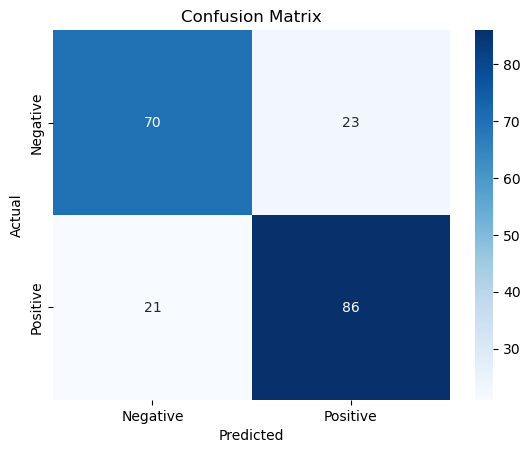

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Classification Report (Precision, Recall, F1-Score)
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

# Confusion Matrix Visualisation
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()